# 1-08 추정 상향 스크리너 — 요즘 실적 전망이 오르는 종목 찾기

**질문 예시:** "최근 예측치 상향된 종목 뭐야?", "요즘 영업이익 전망 내려가는 종목은?"

CHECK 원본(`1_기업펀더멘털/08_추정상향스크리너`)은 컨센서스 스냅샷을 날짜별로 받아 시가총액 상위 60종목의 1개월 리비전을 순위로 냈습니다.
DeepSearch에는 시장 전체 리비전 함수(`GetFundamentalsConsensusChange`)가 이 구독에서 막혀 있어서, **종목별로 증권사 추정치를 받아 직접 계산**합니다.

| 단계 | DeepSearch |
|---|---|
| 유니버스 | 전 종목 시세 1회 호출(`GetStockPrices`)로 시가총액 상위 N |
| 증권사별 추정치 | `SearchFirmFundamentalsForecasts` — **종목별 1회씩** (목록을 넣으면 첫 종목만 옵니다) |
| 컨센서스 | 시점 t에서 "90일 안에 낸 증권사별 최신 추정치"의 평균 (직접 계산) |
| 리비전 | 컨센서스(기준일) ÷ 컨센서스(30일 전) − 1 |

시장 전체 **목표주가** 변화는 한 번 호출로 나옵니다 → [1-11 목표주가·투자의견](11_target_price_opinion.ipynb).

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/1_fundamentals/08_revision_screener.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
UNIVERSE_TOP = 60            # 시가총액 상위 몇 종목을 볼지 (종목당 1회 호출)
METRIC = "operating_income"  # operating_income, net_income, revenue, eps 중 하나
FY = ["202612", "202712"]    # 결산연월. 11월이면 올해(2026)는 거의 확정이라 내년(2027) 리비전을 주로 봅니다
SORT_FY = "202712"
LOOK = 30                    # 리비전 비교 기간(일)
STALE = 90                   # 이보다 오래된 증권사 추정치는 컨센서스에서 뺌(일)
print(PRICE_NOTICE)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


## 1. 유니버스: 시가총액 상위 종목

In [4]:
snap = all_stocks(ASOF)
uni = snap.sort_values("market_cap", ascending=False).head(UNIVERSE_TOP)[["symbol", "name", "market", "industry_name", "market_cap", "close"]]
print(f"기준 {snap['date'].max().date()} — 시가총액 상위 {len(uni)}종목 (일반법인 보통주)")
uni.head(5).assign(market_cap=uni["market_cap"].head(5).map(krw))

기준 2026-11-24 — 시가총액 상위 60종목 (일반법인 보통주)


,symbol,name,market,industry_name,market_cap,close
1733,KRX:005930,삼성전자,KOSPI,이동전화기 제조업,1107.3조,189400
1492,KRX:000660,SK하이닉스,KOSPI,"다이오드, 트랜지스터 및 유사 반도체소자 제조업",818.5조,1158000
884,KRX:402340,SK스퀘어,KOSPI,지주회사,94.3조,715000
189,KRX:373220,LG에너지솔루션,KOSPI,축전지 제조업,73.6조,314500
1631,KRX:009150,삼성전기,KOSPI,그 외 기타 전자부품 제조업,64.1조,858000


## 2. 증권사별 추정치 받기
기준일 30일 전 시점의 컨센서스도 계산해야 하므로 `LOOK + STALE`일 전부터 받습니다. 종목마다 한 번씩 부릅니다(약 0.5초/종목).

In [5]:
from datetime import timedelta
asof = pd.Timestamp(ASOF)
start = (asof - timedelta(days=LOOK + STALE)).date()
frames, failed = [], []  # noqa
for sym in uni["symbol"]:
    try:
        f = ds_df(f'SearchFirmFundamentalsForecasts({sym}, last_only=False, accounting_types="K", '
                  f'date_from={start}, date_to={ASOF})')
    except DSError as e:
        failed.append((sym, str(e)[:80]))
        continue
    if not f.empty and f.notna().any().any():
        f["symbol"] = sym
        frames.append(f.dropna(axis=1, how="all"))
fc = pd.concat(frames, ignore_index=True)
# 연결 추정치(csd_)가 없으면 별도 추정치를 씁니다 (예: 삼성바이오로직스는 csd_ 영업이익이 비어 있음)
fc["value"] = fc[f"csd_{METRIC}"].where(fc[f"csd_{METRIC}"].notna(), fc[METRIC]) if f"csd_{METRIC}" in fc else fc[METRIC]
fc = fc[fc["forecast_date"].isin(FY)].dropna(subset=["value"])
print(f"추정치 {len(fc):,}행, 종목 {fc['symbol'].nunique()}개, 증권사 {fc['inst_code'].nunique()}곳, 실패 {len(failed)}")

추정치 1,015행, 종목 57개, 증권사 11곳, 실패 0


## 3. 컨센서스와 리비전 계산
- **컨센서스(t)** = t 이전 `STALE`일 안에 낸 증권사별 최신 추정치의 평균, **증권사 수**도 함께
- **리비전** = 컨센서스(기준일) ÷ 컨센서스(30일 전) − 1. 두 시점 모두 증권사 2곳 이상일 때만 계산
- **마지막 상향일**: 어떤 증권사가 같은 연도 추정치를 직전보다 올린 가장 최근 날짜
- **⚠**: 30일 전 컨센서스가 0 이하이거나 변화가 ±30%를 넘음(적자·흑자 전환 근처라 %가 과장될 수 있음)
- **이상치 제거**: 증권사 추정치에는 입력 오류가 섞여 있습니다(예: 카카오 2027 영업이익을 한 증권사가 12.2조로 10배 입력,
  대한항공은 한 증권사 영업이익 칸에 매출 20.9조). 같은 시점 증권사들의 **중앙값의 1/3~3배를 벗어난 값은 빼고** 평균을 냅니다.

In [6]:
def clean(values):
    """중앙값의 1/3~3배 밖 값 제거 (중앙값이 양수이고 3곳 이상일 때만)."""
    med = values.median()
    if len(values) >= 3 and med > 0:
        return values[(values >= med / 3) & (values <= med * 3)]
    return values

def consensus(df, t):
    d = df[(df["date"] <= t) & (df["date"] > t - timedelta(days=STALE))]
    last = d.sort_values("date").groupby("inst_code").tail(1)["value"]
    kept = clean(last)
    return kept.mean(), len(kept), len(last) - len(kept)

def last_change(df, up=True):
    d = df.sort_values("date").copy()
    d["prev"] = d.groupby("inst_code")["value"].shift()
    hit = d[(d["value"] > d["prev"]) if up else (d["value"] < d["prev"])]
    return hit["date"].max() if len(hit) else pd.NaT

rows = []
for (sym, fy), g in fc.groupby(["symbol", "forecast_date"]):
    now, n_now, x_now = consensus(g, asof)
    prev, n_prev, x_prev = consensus(g, asof - timedelta(days=LOOK))
    rev = now / prev - 1 if n_now >= 2 and n_prev >= 2 and prev else None
    rows.append({"symbol": sym, "FY": fy, "컨센서스": now, "증권사": n_now, "30일전": prev, "30일전 증권사": n_prev,
                 "리비전": rev, "이상치 제외": x_now + x_prev, "마지막 상향일": last_change(g, True), "마지막 하향일": last_change(g, False),
                 "⚠": "⚠" if rev is not None and (prev <= 0 or abs(rev) > 0.3) else ""})
rv = pd.DataFrame(rows).merge(uni, on="symbol")
wide = rv.pivot_table(index="symbol", columns="FY", values="리비전")
print("리비전 계산 가능 종목:", {fy: int(wide[fy].notna().sum()) for fy in FY if fy in wide})
print("이상치로 뺀 추정치가 있는 종목:", ", ".join(rv.loc[rv["이상치 제외"] > 0, "name"].unique()))

리비전 계산 가능 종목: {'202612': 51, '202712': 50}
이상치로 뺀 추정치가 있는 종목: 대한항공, 포스코퓨처엠, SK, 카카오


## 4. 상향 상위 / 하향 상위 (내년 영업이익 기준)

In [7]:
def table(df):
    out = df[["name", "industry_name", "리비전", "⚠", "컨센서스", "증권사", "이상치 제외", "마지막 상향일", "마지막 하향일"]].copy()
    out["리비전"] = (out["리비전"] * 100).map(lambda x: f"{x:+.1f}%")
    out["컨센서스"] = out["컨센서스"].map(krw)
    for c in ("마지막 상향일", "마지막 하향일"):
        out[c] = out[c].dt.date
        out[c + " 경과일"] = (asof - df[c]).dt.days.astype("Int64")
    return out.rename(columns={"name": "종목", "industry_name": "업종"})

main = rv[(rv["FY"] == SORT_FY) & rv["리비전"].notna()].sort_values("리비전", ascending=False)
print(f"■ {SORT_FY[:4]}년 {METRIC} 1개월 리비전 상향 상위 (기준 {ASOF})")
display(table(main.head(15)))
print(f"■ 하향 상위")
display(table(main.sort_values("리비전").head(10)))

■ 2027년 operating_income 1개월 리비전 상향 상위 (기준 2026-11-24)


,종목,업종,리비전,⚠,컨센서스,증권사,이상치 제외,마지막 상향일,마지막 하향일,마지막 상향일 경과일,마지막 하향일 경과일
37,HMM,외항 화물 운송업,+48.5%,⚠,1.6조,3,0,2026-11-13,2026-08-14,11,102
35,S-Oil,원유 정제처리업,+28.4%,,3.7조,4,0,2026-11-03,NaT,21,<NA>
57,삼성생명,생명 보험업,+16.1%,,7.1조,3,0,2026-11-13,NaT,11,<NA>
85,SK이노베이션,석유 정제품 제조업,+14.2%,,7.6조,5,0,2026-10-30,NaT,25,<NA>
25,삼성전기,그 외 기타 전자부품 제조업,+11.9%,,4.8조,5,0,2026-11-19,NaT,5,<NA>
7,대한항공,항공 여객 운송업,+7.0%,,2.2조,5,1,2026-11-23,2026-10-27,1,28
3,SK하이닉스,"다이오드, 트랜지스터 및 유사 반도체소자 제조업",+6.1%,,463.8조,5,0,2026-10-29,NaT,26,<NA>
53,삼성물산,직물 도매업,+4.4%,,4.6조,5,0,2026-10-29,2026-10-29,26,26
19,삼성전자,이동전화기 제조업,+4.1%,,619.0조,7,0,2026-10-30,2026-10-02,25,53
79,셀트리온,의약용 화합물 및 항생물질 제조업,+3.9%,,2.4조,7,0,2026-11-03,2026-10-23,21,32


■ 하향 상위


,종목,업종,리비전,⚠,컨센서스,증권사,이상치 제외,마지막 상향일,마지막 하향일,마지막 상향일 경과일,마지막 하향일 경과일
43,한국전력,송전 및 배전업,-34.8%,⚠,7.1조,8,0,2026-11-13,2026-11-16,11,8
95,에코프로비엠,축전지 제조업,-33.5%,⚠,"1,200억",2,0,NaT,2026-11-09,<NA>,15
111,LG에너지솔루션,축전지 제조업,-26.1%,,3.0조,4,0,2026-10-15,2026-11-04,40,20
31,고려아연,"연 및 아연 제련, 정련 및 합금 제조업",-20.4%,,1.4조,3,0,NaT,2026-11-06,<NA>,18
1,기아,승용차 및 기타 여객용 자동차 제조업,-18.0%,,8.9조,6,0,NaT,2026-11-02,<NA>,22
27,HD한국조선해양,지주회사,-15.0%,,7.0조,3,0,NaT,2026-10-29,<NA>,26
11,포스코퓨처엠,축전지 제조업,-12.4%,,"1,510억",2,1,2026-11-04,2026-11-03,20,21
69,한화오션,선박 및 수상 부유 구조물 건조업,-12.2%,,2.2조,6,0,NaT,2026-11-12,<NA>,12
65,NAVER,포털 및 기타 인터넷 정보매개 서비스업,-10.6%,,2.3조,5,0,NaT,2026-11-13,<NA>,11
41,한화에어로스페이스,항공기용 부품 제조업,-9.8%,,5.3조,7,0,NaT,2026-11-02,<NA>,22


## 5. 올해 vs 내년 리비전 비교
두 해 모두 오르면 "실적 눈높이가 전반적으로 올라가는 중", 올해만 오르면 이미 나온 분기 실적 반영일 가능성이 큽니다.

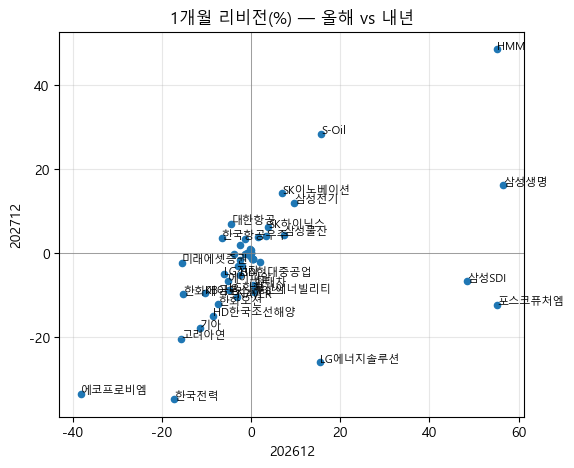

In [8]:
both = wide.dropna().merge(uni[["symbol", "name"]], left_index=True, right_on="symbol").set_index("name")[FY]
ax = (both * 100).plot.scatter(x=FY[0], y=FY[1], figsize=(6, 5), title="1개월 리비전(%) — 올해 vs 내년")
for n, r in (both * 100).iterrows():
    if abs(r[FY[0]]) > 5 or abs(r[FY[1]]) > 5:
        ax.annotate(n, (r[FY[0]], r[FY[1]]), fontsize=8)
ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5); ax.grid(alpha=.3)

## 결과 읽는 법과 한계
- 리비전 %는 **같은 증권사 집합의 평균이 어떻게 바뀌었나**입니다. 30일 사이 새 증권사가 들어오거나 빠지면 그 효과도 섞입니다(증권사 수 열 참고).
- 증권사 추정치에는 단위·필드 입력 오류가 섞여 있어 중앙값 기준으로 걸렀습니다. 증권사가 2곳뿐이면 거를 수 없으니 `증권사` 열을 같이 보세요.
- DeepSearch가 받는 증권사는 대형주도 4~7곳이라 시장 전체 컨센서스보다 표본이 작습니다. 증권사 2곳 미만 종목은 뺐습니다.
- `⚠` 종목은 이익이 0 근처라 %가 크게 튈 수 있습니다. 절대 금액(컨센서스 열)을 같이 보세요.
- 유니버스를 늘리면 종목당 1회씩 호출이 늘어납니다(100종목 ≈ 1분).